# Clase 2 — Evaluación de Prophet: millas recorridas en EE. UU.

Datos: `Data/Miles_Traveled.csv` — millas recorridas por vehículos en EE. UU. por mes, de enero 1970 a **agosto 2026** (680 meses, datos actualizados de FRED).

1. **Forma clásica:** separar train/test y calcular el **RMSE**.
2. **Herramienta de Prophet:** **validación cruzada** (*cross validation*).

Documentación: https://facebook.github.io/prophet/docs/diagnostics.html

## Paso 1: Importar y leer los datos

In [1]:
import pandas as pd
from prophet import Prophet          # en el video: from fbprophet import Prophet
import matplotlib.pyplot as plt
%matplotlib inline

df = pd.read_csv('Data/Miles_Traveled.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 680 entries, 0 to 679
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   observation_date  680 non-null    str  
 1   TRFVOLUSM227NFWA  680 non-null    int64
dtypes: int64(1), str(1)
memory usage: 10.8 KB


## Paso 2: Preparar el formato que pide Prophet

In [2]:
df.columns = ['ds', 'y']
df['ds'] = pd.to_datetime(df['ds'])
df.head()

,ds,y
0,1970-01-01,80173
1,1970-02-01,77442
2,1970-03-01,90223
3,1970-04-01,89956
4,1970-05-01,97972


## Paso 3: Mirar los datos

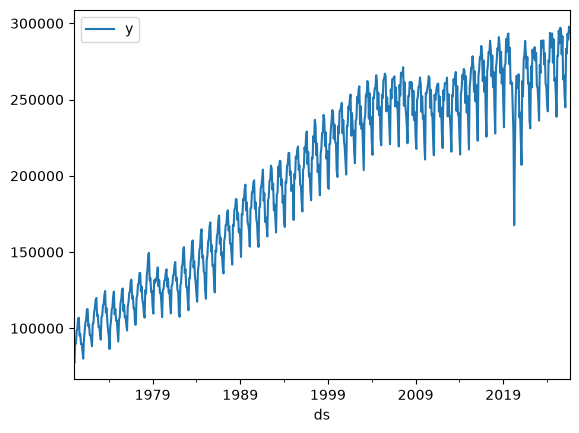

In [3]:
df.plot(x='ds', y='y');

## Paso 4: Separar entrenamiento y prueba

In [4]:
len(df)

680

In [5]:
train = df.iloc[:668]     # 680 - 12 = 668   (en el video: 588 - 12 = 576)
test  = df.iloc[668:]     # los últimos 12 meses (sep 2025 -> ago 2026)
test

,ds,y
668,2025-09-01,279611
669,2025-10-01,291540
670,2025-11-01,263138
671,2025-12-01,265855
672,2026-01-01,252805
673,2026-02-01,244934
674,2026-03-01,283246
675,2026-04-01,280116
676,2026-05-01,293169
677,2026-06-01,289387


## Paso 5: Entrenar y predecir (las 4 líneas clave)

In [6]:
m = Prophet()
m.fit(train)
future = m.make_future_dataframe(periods=12, freq='MS')
forecast = m.predict(future)

22:59:28 - cmdstanpy - INFO - Chain [1] start processing


22:59:28 - cmdstanpy - INFO - Chain [1] done processing


## Paso 6: Ver las predicciones

In [7]:
forecast.tail()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
675,2026-04-01,275014.393148,264973.073285,282963.422274,274972.004466,275027.077860,-1104.100156,-1104.100156,-1104.100156,-1104.100156,-1104.100156,-1104.100156,0.0,0.0,0.0,273910.292992
676,2026-05-01,275155.131573,275163.747587,293986.195505,275092.206350,275180.283469,10019.103691,10019.103691,10019.103691,10019.103691,10019.103691,10019.103691,0.0,0.0,0.0,285174.235264
677,2026-06-01,275300.561278,275776.854480,294453.442370,275207.984092,275338.936582,9794.440095,9794.440095,9794.440095,9794.440095,9794.440095,9794.440095,0.0,0.0,0.0,285095.001373
678,2026-07-01,275441.299703,282639.937199,301059.691146,275329.581272,275501.946877,16469.086157,16469.086157,16469.086157,16469.086157,16469.086157,16469.086157,0.0,0.0,0.0,291910.385860
679,2026-08-01,275586.729408,283066.887944,301541.871130,275446.209575,275666.275209,16785.217272,16785.217272,16785.217272,16785.217272,16785.217272,16785.217272,0.0,0.0,0.0,292371.946681


## Paso 7: Graficar predicción vs. realidad

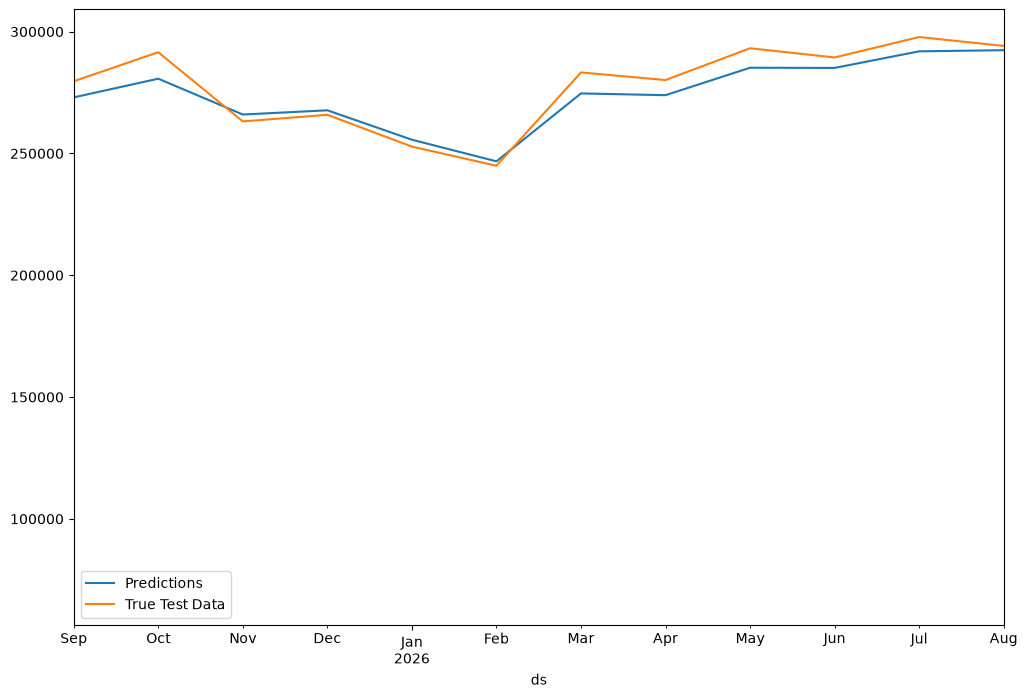

In [8]:
ax = forecast.plot(x='ds', y='yhat', label='Predictions', legend=True, figsize=(12, 8))
test.plot(x='ds', y='y', label='True Test Data', legend=True, ax=ax,
          xlim=(pd.Timestamp('2025-09-01'), pd.Timestamp('2026-08-01')));   # en el video: xlim=('2018-01-01','2019-01-01')

## Paso 8: Medir el error con números (RMSE)

In [9]:
from statsmodels.tools.eval_measures import rmse

predictions = forecast.iloc[-12:]['yhat']
predictions

668    272999.226074
669    280670.652401
670    265967.074930
671    267697.864176
672    255625.432009
673    246750.938688
674    274625.930641
675    273910.292992
676    285174.235264
677    285095.001373
678    291910.385860
679    292371.946681
Name: yhat, dtype: float64

In [10]:
test['y']

668    279611
669    291540
670    263138
671    265855
672    252805
673    244934
674    283246
675    280116
676    293169
677    289387
678    297770
679    294124
Name: y, dtype: int64

In [11]:
rmse(predictions, test['y'])

np.float64(5895.428081927206)

In [12]:
test.mean()

ds    2026-02-14 20:00:00
y           277974.583333
dtype: object

## Paso 9: Importar las herramientas de validación cruzada

In [13]:
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import plot_cross_validation_metric

## Paso 10: Definir los parámetros (formato `pd.Timedelta`, en días)

In [14]:
# INITIAL: 5 años
initial = 5 * 365
initial = str(initial) + ' days'
initial

'1825 days'

In [15]:
# PERIOD: cada 5 años
period = 5 * 365
period = str(period) + ' days'

# HORIZON: 1 año
horizon = 365
horizon = str(horizon) + ' days'

period, horizon

('1825 days', '365 days')

In [16]:
pd.Timedelta(initial)

Timedelta('1825 days 00:00:00')

## Paso 11: Ejecutar la validación cruzada

In [17]:
df_cv = cross_validation(m, initial=initial, period=period, horizon=horizon)

  0%|          | 0/10 [00:00<?, ?it/s]

22:59:29 - cmdstanpy - INFO - Chain [1] start processing


22:59:29 - cmdstanpy - INFO - Chain [1] done processing


22:59:29 - cmdstanpy - INFO - Chain [1] start processing


22:59:29 - cmdstanpy - INFO - Chain [1] done processing


22:59:29 - cmdstanpy - INFO - Chain [1] start processing


... (11 outputs left out)

22:59:30 - cmdstanpy - INFO - Chain [1] start processing


22:59:30 - cmdstanpy - INFO - Chain [1] done processing


22:59:31 - cmdstanpy - INFO - Chain [1] start processing


22:59:31 - cmdstanpy - INFO - Chain [1] done processing


## Paso 12: Ver la tabla de la validación cruzada

In [18]:
df_cv.head()

,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,1979-09-01,132468.411909,129519.438246,135326.425036,127576,1979-08-13
1,1979-10-01,134444.800367,131515.025839,137558.935121,131619,1979-08-13
2,1979-11-01,126170.651607,123067.604871,129194.231959,123381,1979-08-13
3,1979-12-01,125926.839101,122843.987563,128931.053469,123226,1979-08-13
4,1980-01-01,120623.982751,117679.446490,123682.904243,116462,1979-08-13


In [19]:
len(df_cv)

120

In [20]:
df_cv['cutoff'].unique()

<DatetimeArray>
['1979-08-13 00:00:00', '1984-08-11 00:00:00', '1989-08-10 00:00:00',
 '1994-08-09 00:00:00', '1999-08-08 00:00:00', '2004-08-06 00:00:00',
 '2009-08-05 00:00:00', '2014-08-04 00:00:00', '2019-08-03 00:00:00',
 '2024-08-01 00:00:00']
Length: 10, dtype: datetime64[us]

## Paso 13 (extra): Dibujar los cortes sobre los datos

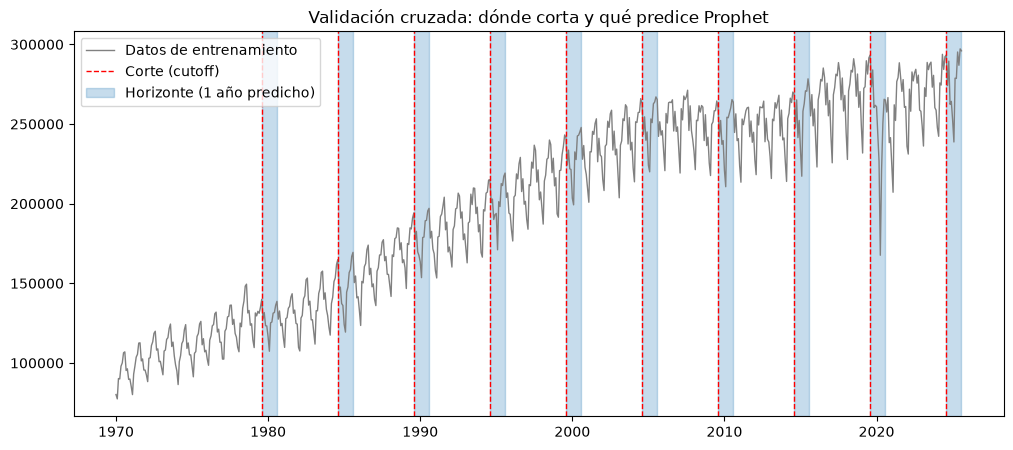

In [21]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train['ds'], train['y'], color='gray', lw=1, label='Datos de entrenamiento')
for i, c in enumerate(df_cv['cutoff'].unique()):
    c = pd.Timestamp(c)
    ax.axvline(c, color='red', ls='--', lw=1, label='Corte (cutoff)' if i == 0 else None)
    ax.axvspan(c, c + pd.Timedelta(horizon), color='tab:blue', alpha=0.25,
               label='Horizonte (1 año predicho)' if i == 0 else None)
ax.set_title('Validación cruzada: dónde corta y qué predice Prophet')
ax.legend();

## Paso 14: Las métricas de error

In [22]:
performance_metrics(df_cv)

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,51 days,2.216066e+07,4707.511545,3380.074198,0.016492,0.013687,0.016305,0.750000
1,52 days,2.035618e+07,4511.782237,3098.255160,0.013985,0.010907,0.013862,0.833333
2,53 days,2.061251e+07,4540.099932,3190.670190,0.014308,0.011556,0.014187,0.833333
3,54 days,2.251316e+07,4744.803415,3538.966330,0.015726,0.013687,0.015624,0.750000
4,56 days,2.187907e+07,4677.507170,3331.806672,0.014668,0.011556,0.014558,0.750000
...,...,...,...,...,...,...,...,...
104,360 days,9.053921e+07,9515.209353,6970.724213,0.030162,0.023371,0.029753,0.500000
105,361 days,9.890598e+07,9945.148318,7757.023477,0.033128,0.027751,0.032659,0.416667
106,362 days,1.030617e+08,10151.933266,8190.391804,0.034707,0.027751,0.034272,0.333333
107,364 days,1.497392e+08,12236.796586,9633.658632,0.040154,0.030377,0.039403,0.333333


## Paso 15: Graficar el error RMSE

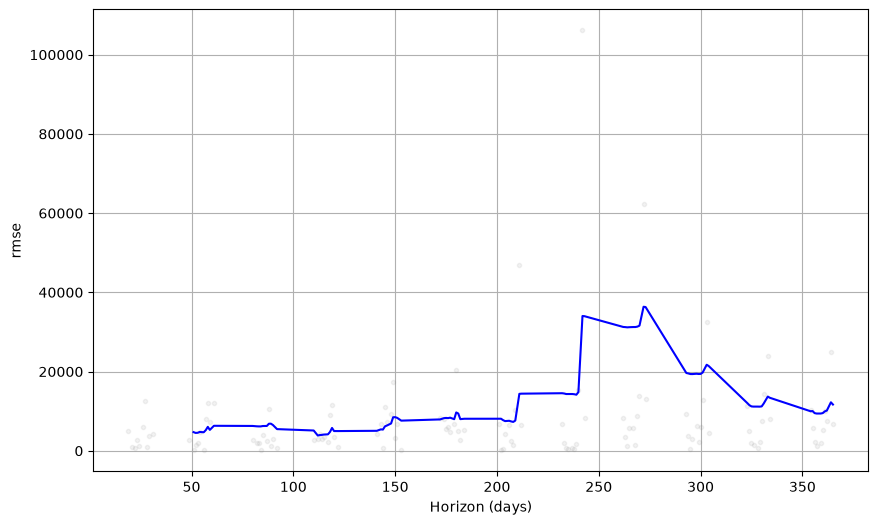

In [23]:
plot_cross_validation_metric(df_cv, metric='rmse');

## Paso 16: Graficar el error en porcentaje (MAPE)

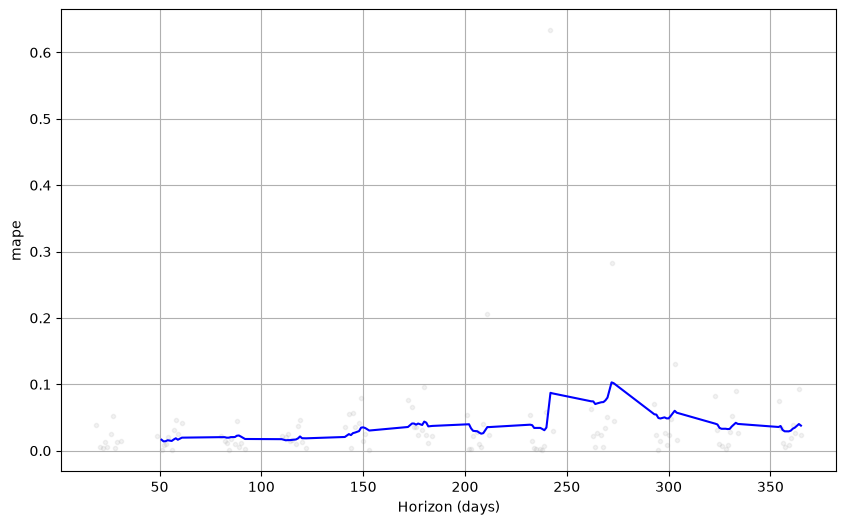

In [24]:
plot_cross_validation_metric(df_cv, metric='mape');

## Paso 17 (extra): Resumen en una sola cifra

In [25]:
print('MAPE promedio  :', round(df_cv.eval('abs(y - yhat) / y').mean() * 100, 2), '%')
print('Cobertura real :', round(((df_cv.y >= df_cv.yhat_lower) & (df_cv.y <= df_cv.yhat_upper)).mean() * 100, 1), '%')

MAPE promedio  : 3.58 %
Cobertura real : 50.0 %
